# Two-stage stochastic model: what site cap should we commit to?

**Decision problem.** A site pays a monthly **demand charge** on its peak power. Before the month starts it must commit to a power cap $C$ (stage 1). Each day, after seeing which cars arrive, it schedules charging under that cap (stage 2). Energy that can't be delivered under the cap is penalized.

$$
\min_{C \ge 0}\; c\,C \;+\; \frac{1}{S}\sum_{s=1}^{S} \lambda\, U_s(C),
\qquad
U_s(C) = \min_{r,\,u \ge 0} \Big\{ \textstyle\sum_i u_i \;:\; 0\le r_{it}\le a_{it}p_i,\;\; \sum_t r_{it}\Delta t + u_i = E_i,\;\; \sum_i r_{it} \le C\;\forall t \Big\}
$$

- **Scenarios $s$** = historical weekdays (sample average approximation, SAA). Train: 2019 (260 weekdays). Test: Jan–Feb 2020 (43 weekdays).
- **$c$** = demand charge per weekday = (\$/kW-month) / 21. Base: **\$20/kW-month**, close to SCE TOU-8's facilities-related demand charge (\$19.31–23.71/kW in the tariff schedule; year not confirmed).
- **$\lambda$** = penalty per kWh not delivered. There is no market price for this, so we **sweep it**.
- **Recourse is offline within the day.** Once a day is revealed, all its arrivals and departures are known. The uncertainty modelled is *which day you get*; intraday departure uncertainty is the online extension.

**Solution method.** $C$ is the only first-stage variable, and each $U_s(C)$ is convex, piecewise-linear and non-increasing. So we tabulate every $U_s$ on a 1 kW grid once (warm-started HiGHS), and any $(c,\lambda)$ becomes a 1-D minimization. Section 5 checks this against the textbook extensive form (one LP with all scenarios). Produced by `python -m acn.stochastic --rates uniform|observed`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from acn import plots
plots.style()
pd.set_option("display.precision", 2)
FIGS = ROOT / "results" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

from acn import stochastic as st

DEMAND_CHARGE = 20.0   # $/kW-month (approx. SCE TOU-8 facilities-related demand charge)
LAM_BASE = 1.0         # $/kWh not delivered (illustrative; swept below)
RATES = "observed"     # per-car rates from data (more realistic); "uniform" = all cars 6.656 kW

U_tr, U_te, pk_tr, pk_te = st.load_curves(f"jpl_{RATES}")
pr = st.Prices(DEMAND_CHARGE, LAM_BASE)
print(f"train: {U_tr.shape[0]} weekdays, test: {U_te.shape[0]} weekdays, cap grid 0..{U_tr.columns.max():.0f} kW")
print(f"c = ${pr.c:.3f} per kW per weekday")
d1 = np.diff(U_tr.to_numpy(), axis=1)
print(f"sanity: non-increasing violations {(d1 > 1e-6).sum()}, convexity violations {(np.diff(d1, axis=1) < -1e-5).sum()}")

train: 260 weekdays, test: 43 weekdays, cap grid 0..113 kW
c = $0.952 per kW per weekday
sanity: non-increasing violations 0, convexity violations 0


## 1. Stage 2: how much energy goes undelivered as the cap tightens

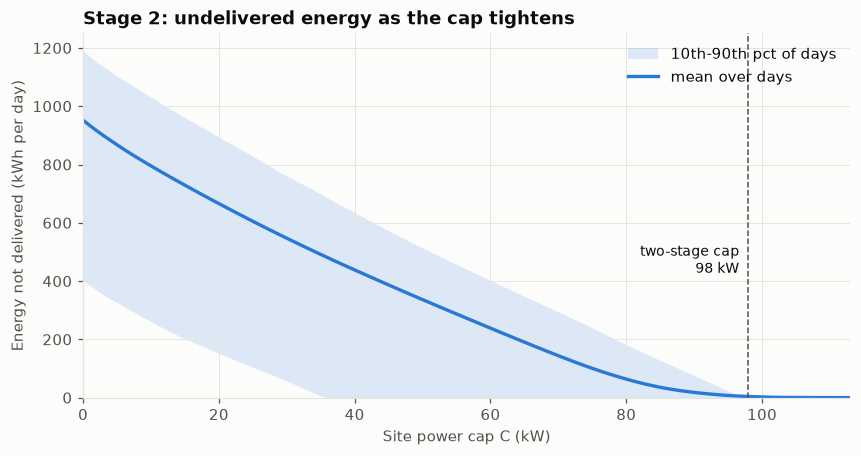

In [2]:
C_star, f_star = st.solve_saa(U_tr, pr)
fig = plots.unmet_curve_plot(U_tr, C_star)
save(fig, "two_stage_unmet_curve")

## 2. Stage 1: the cost trade-off and the optimal cap

Optimal cap C* = 98 kW; expected cost $97.23 per weekday
For reference: daily optimal peaks have mean 77, median 83, 90th pct 97, max 113 kW


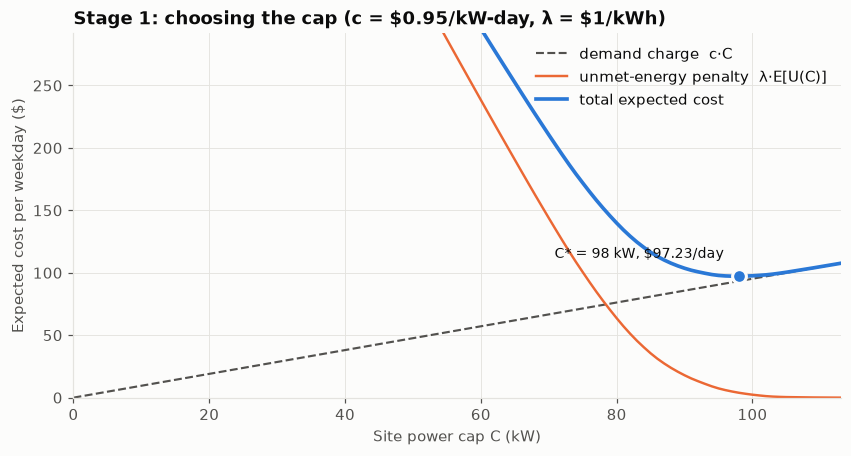

In [3]:
fig = plots.cost_decomposition(U_tr, pr.c, pr.lam)
save(fig, "two_stage_cost_curve")
print(f"Optimal cap C* = {C_star:.0f} kW; expected cost ${f_star:.2f} per weekday")
print(f"For reference: daily optimal peaks have mean {pk_tr.mean():.0f}, median {pk_tr.median():.0f}, "
      f"90th pct {pk_tr.quantile(.9):.0f}, max {pk_tr.max():.0f} kW")

**Intuition (it is a newsvendor problem).** Raising $C$ by 1 kW costs $c$ for sure. It saves $\lambda$ times the expected reduction in unmet energy, which is only non-zero on days whose own optimal peak exceeds $C$. So $C^*$ sits at a **quantile of the daily-peak distribution** that rises with $\lambda/c$.

,0.1,0.3,1.0,3.0,10.0,30.0,100.0
C* (kW),64.00,88.00,98.00,103.00,105.00,113.0,113.0
share of training days fully served,0.14,0.69,0.91,0.97,0.99,1.0,1.0


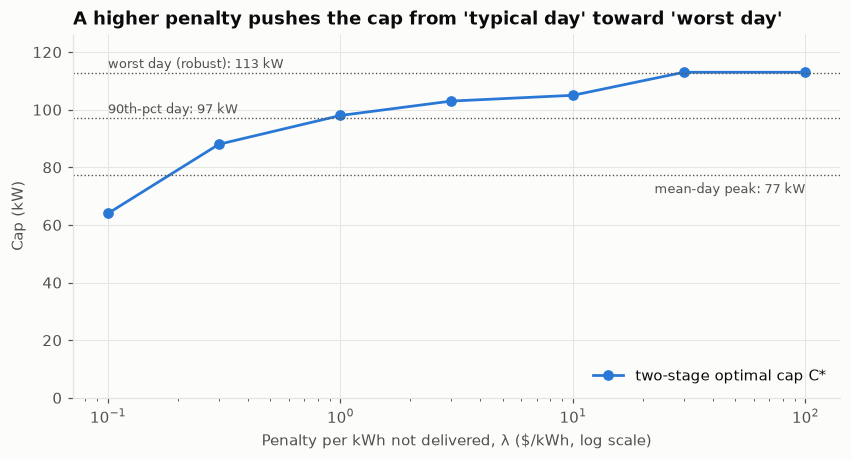

In [4]:
lams = np.array([0.1, 0.3, 1, 3, 10, 30, 100])
caps = pd.Series([st.solve_saa(U_tr, st.Prices(DEMAND_CHARGE, l))[0] for l in lams], index=lams)
fig = plots.cap_vs_penalty(caps, pk_tr)
save(fig, "two_stage_cap_vs_penalty")
display(pd.DataFrame({"C* (kW)": caps,
                      "share of training days fully served": [(pk_tr <= c + 1e-9).mean() for c in caps]}).T)

## 3. Value of the stochastic solution (VSS) and of perfect information (EVPI)

In [5]:
tbl = pd.DataFrame({l: st.evpi_vss(U_tr, pk_tr, st.Prices(DEMAND_CHARGE, l)) for l in lams}).T
tbl.index.name = "lambda ($/kWh)"
display(tbl.round(2))

,RP,WS,EEV,EVPI,VSS
lambda ($/kWh),,,,,
0.1,80.96,73.47,82.04,7.49,1.08
0.3,90.97,74.00,97.54,16.97,6.56
1.0,97.23,74.15,151.79,23.09,54.55
3.0,100.61,74.18,306.80,26.43,206.19
10.0,104.43,74.19,849.32,30.24,744.89
30.0,107.62,74.19,2399.40,33.43,2291.78
100.0,107.62,74.19,7824.66,33.42,7717.04


Units: \$ per weekday.
- **RP** (recourse problem): the two-stage optimum.
- **WS** (wait-and-see): each day picks its own cap knowing the day in advance, so it is a lower bound.
- **EEV**: commit to the cap that is optimal for the *mean* day (the mean of daily optimal peaks), then live with every day's outcome.
- **EVPI = RP − WS**: what perfect day-ahead knowledge would be worth.
- **VSS = EEV − RP**: what you lose by planning for an average day instead of the distribution. It explodes as $\lambda$ grows, because a mean-day cap leaves energy undelivered on roughly two-thirds of days.

## 4. Out-of-sample: commit using 2019, live through Jan–Feb 2020

,policy,split,cap_kw,expected_cost,demand_cost,unmet_cost,mean_unmet_kwh,days_with_unmet
0,two-stage (SAA),train,98.0,97.23,93.33,3.90,3.90,0.09
1,two-stage (SAA),test,98.0,98.42,93.33,5.09,5.09,0.12
2,mean-day plan (EV),train,78.0,151.79,74.29,77.50,77.50,0.67
3,mean-day plan (EV),test,78.0,180.09,74.29,105.80,105.80,0.70
4,median-day plan,train,84.0,120.35,80.00,40.35,40.35,0.47
5,median-day plan,test,84.0,142.67,80.00,62.67,62.67,0.63
6,worst-case plan (robust),train,113.0,107.62,107.62,0.00,0.00,0.00
7,worst-case plan (robust),test,113.0,107.62,107.62,0.00,0.00,0.00
8,wait-and-see (perfect info),train,NaN,74.15,NaN,NaN,NaN,NaN
9,wait-and-see (perfect info),test,NaN,74.36,NaN,NaN,NaN,NaN


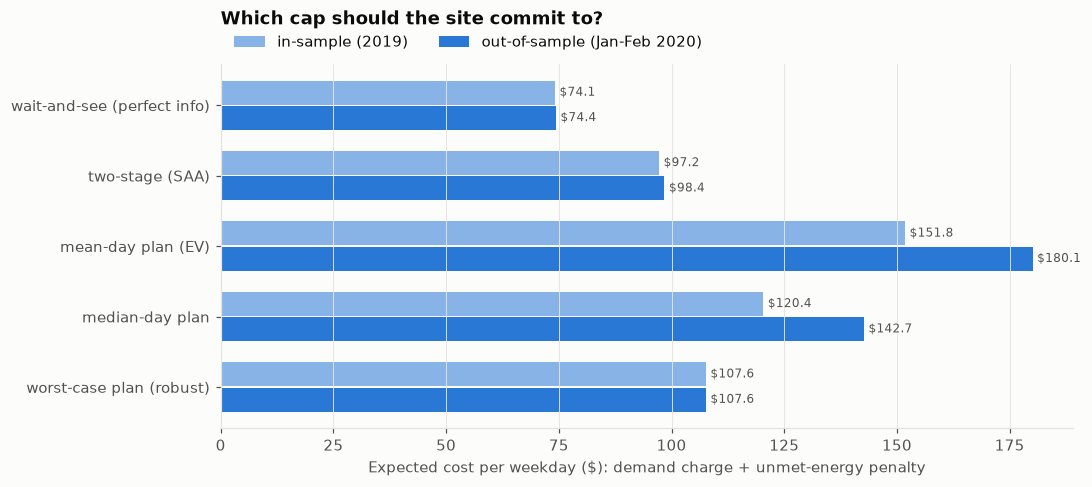

In [6]:
pol = st.policy_table(U_tr, U_te, pk_tr, pr)
display(pol.round(2))
fig = plots.policy_costs(pol)
save(fig, "two_stage_policies")

Policies, all choosing the cap from 2019 data only:
- **two-stage (SAA)**: minimizes expected cost over the 2019 scenarios.
- **mean-day / median-day plan**: size the cap for a typical day.
- **worst-case (robust)**: size for the busiest 2019 day; never short in sample.
- **wait-and-see**: the unreachable perfect-information benchmark.

At most penalties the two-stage cap lands between the typical-day and worst-day plans. It beats both out of sample, though the test set is only 43 weekdays.

## 5. Validation: the grid method matches the extensive-form LP

In [7]:
from acn.stochastic import extensive_form, load_scenarios, unmet_curves
inst, peaks = load_scenarios("jpl", "2019-03-04", "2019-03-22", rates=RATES)
U_small = unmet_curves(inst, np.arange(0, np.ceil(peaks.max()) + 0.25, 0.25), peaks.to_dict())
rows = []
for l in [0.3, 3, 30]:
    p = st.Prices(DEMAND_CHARGE, l)
    Cg, fg = st.solve_saa(U_small, p)
    Ce, fe = extensive_form(inst, p)
    rows.append({"lambda": l, "grid C*": Cg, "grid cost": fg, "extensive C*": Ce, "extensive cost": fe,
                 "abs cost gap": abs(fg - fe)})
display(pd.DataFrame(rows).round(4))
print(f"{len(inst)} scenarios; extensive form = one LP with all scenarios' variables and a shared C")

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


,lambda,grid C*,grid cost,extensive C*,extensive cost,abs cost gap
0,0.3,92.5,90.54,92.52,90.54,1.90e-03
1,3.0,98.5,93.81,98.43,93.74,6.75e-02
2,30.0,98.5,93.81,98.43,93.74,6.75e-02


15 scenarios; extensive form = one LP with all scenarios' variables and a shared C


## 6. Limitations
1. **Offline recourse.** Within a day the scheduler knows every departure. Real-time departure uncertainty would raise unmet energy at any cap; that is the next extension (rolling horizon, or using drivers' estimated departures).
2. **Days are independent and equally likely.** Seasonality and trends (2020 was busier than early 2019) are only checked by the train/test split.
3. **λ is a modelling choice.** Results are shown across a range rather than relying on one value.
4. **The demand charge is approximate** (SCE TOU-8 facilities-related demand, year unverified). Time-of-use energy prices are ignored here; adding them is the prices extension.
5. **The cap is fixed for the whole period.** A real tariff charges the maximum demand actually reached; a fixed, never-exceeded cap is a conservative stand-in for that.